## กีฬาสี

### โจทย์ บริษัทแห่งหนึ่งจัดงานกีฬาสีเชื่อมความสัมพันธ์โดยใช้วิธี Genetic
- สีแบ่งออกเป็น $สีแดง$ | $สีน้ำเงิน$ 
- ต้องมีความเท่าเทียม เช่น เพศ อายุ น้ำหนัก ส่วนสูง
- ต้องคละ department เท่า ๆ กันในแต่ละสี
### ผลลัพธ์ที่ต้องการ
- visualization ของแต่ละคนในแต่ละสี ต้องระบุว่าสีนั้น ๆ มีพนักงานคนั้นมีใครบ้าง

# ขั้นตอนการทำ

#### import ไลบรารีที่ใช้

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.stats import wasserstein_distance

#### ให้ employee_id กับ พนักงาน

In [22]:
# โหลดชุดข้อมูล HR.csv
df = pd.read_csv('HR.csv')

# ตัดช่องว่างหัวท้ายข้อความของคอลัมน์สตริง
df['gender'] = df['gender'].astype(str).str.strip()
df['department'] = df['department'].astype(str).str.strip()

# สร้าง employee_id ให้พนักงานแต่ละคน (เช่น EMP_001, EMP_002, ...)
df.insert(0, 'employee_id', [f'EMP_{i+1:03d}' for i in range(len(df))])

# แสดงจำนวนและตัวอย่างข้อมูล
print(f'จำนวนพนักงานทั้งหมด: {len(df)} คน')
df.head(10)

จำนวนพนักงานทั้งหมด: 358 คน


,employee_id,gender,department,weight,height,age
0,EMP_001,Male,R,89,172,32
1,EMP_002,Male,R,89,180,52
2,EMP_003,Male,R,52,158,27
3,EMP_004,Male,R,50,157,39
4,EMP_005,Male,R,68,174,25
5,EMP_006,Male,R,62,164,29
6,EMP_007,Male,R,74,168,53
7,EMP_008,Male,R,64,164,47
8,EMP_009,Male,R,58,166,60
9,EMP_010,Female,R,81,178,36


#### กำหนด DNA

- จากทั้งหมด 358 คน แบ่งออกได้เป็น สีแดง 179(0) | สีน้ำเงิน 179(1) 
- ให้ยืนมีแค่าเป็น {Ci1, Ci2, ..., Cin} Ci คือ กลุ่มทีมของพนักงานคนที่ i มีค่าเป็น 0 และ 1

In [23]:
'''
# สร้างโครโมโซมเริ่มต้นแบบสุ่ม size ชุด แต่ละชุดยาว len(df) การันตีอัตราส่วน 0:1 = 179:179
def generate_pop_simetry(size, n_employees = len(df)):

    #แบ่งจำนวนของแต่ละทีมที่ควรมี
    NUM_RED = n_employees // 2        
    NUM_BLUE = n_employees - NUM_RED   
    # สร้าง [0 1] ตามจำนวนที่กำหนดแบบเรียงกัน
    base_dna = np.array([0] * NUM_RED + [1] * NUM_BLUE) 
    # คืนค่าเป็นการสลับแบบสุ่มโดยผลรวมยังเท่ากัน
    return np.array([np.random.permutation(base_dna) for _ in range(size)])
'''

# สร้างโครโมโซมเริ่มต้นแบบสุ่ม size ชุด แต่ละชุดยาว len(df) แบบสุ่มทั้งหมด (0 หรือ 1 อิสระ)
def generate_pop_asimetry(size, n_employees = len(df)):
    return np.random.randint(0, 2, size=(size, n_employees))

# สร้างประชากรเริ่มต้น 100 คน
pop = generate_pop_asimetry(100)

print(f"ขนาดประชากร: {pop.shape}")  # (100, 358)
print("ตัวอย่าง DNA ตัวแรก: \n", pop[0])


ขนาดประชากร: (100, 358)
ตัวอย่าง DNA ตัวแรก: 
 [1 0 0 0 0 1 1 0 1 1 0 0 1 0 0 1 1 0 1 1 1 1 0 0 1 1 1 1 0 1 1 0 0 1 1 0 0
 1 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 1 0 1 1 0 1 0 1 0 1 0 0 0 0 0
 1 1 1 1 0 0 0 0 1 0 0 1 0 1 1 1 1 0 0 0 1 0 1 0 0 1 0 0 1 0 1 1 0 0 1 1 1
 0 1 0 1 0 0 0 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 1 0 1 0 0 1 0 1 0 1 0 0 1 0 1
 0 0 0 0 0 1 1 1 0 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 1 1 0 0 0 0 0 0 0 1 1 0 0
 1 1 0 0 1 0 0 1 1 0 0 0 0 0 0 0 1 1 1 0 0 1 0 0 0 1 0 1 1 1 1 0 0 1 0 0 0
 0 0 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 0 0 0 0 1 1 1 0 1 1 0 0 0 0 0 1 1 0 1 0
 0 0 1 0 0 1 1 1 1 0 1 1 0 1 0 1 1 0 0 1 0 1 0 0 0 0 1 1 1 0 1 0 1 1 1 0 1
 1 1 0 0 1 0 0 1 0 0 1 1 1 1 0 0 0 1 0 1 1 1 0 0 0 0 0 0 0 1 1 0 0 1 0 0 1
 0 1 0 0 1 1 0 1 1 1 0 1 1 0 0 0 0 1 0 0 1 0 0 0 0]


#### วัดผล
- กลุ่มจำนวนต่อเนื่อง
    - จำนวน : N(0) - N(1) สำคัญมาก *10 
    - อายุ : Mean(อายุ 0) - Mean(อายุ 1) 
    - น้ำหนัก : Mean(น้ำหนัก 0) - Mean(น้ำหนัก 1) 
    - ส่วนสูง : Mean(ส่วนสูง 0) - Mean(ส่วนสูง 1) 
- กลุ่มการกระจายตัว
    - เพศ : N(ผู้ชาย 0) - N(ผู้ชาย 1) ที่เหลือเป้นผู้หญิง
    - แผนก : หาผลรวมของ N(Di0) - (Di1) โดย Di คือแผนกนั้น ๆ

In [24]:
# แปลงข้อมูลเป็น NumPy Array ล่วงหน้า เพื่อให้คำนวณได้รวดเร็ว
weights = df['weight'].values
heights = df['height'].values
ages = df['age'].values
is_male = (df['gender'] == 'Male').values.astype(int)
dept_dummies = pd.get_dummies(df['department']).values

# input: โครโมโซม 1 ตัว 
# process: คำนวณความไม่เท่าเทียม (จำนวนคน, อายุ, น้ำหนัก, ส่วนสูง, เพศ, แผนก)
# output: ความไม่เท่าเทียม total_error (ยิ่งน้อยยิ่งดี)
def evaluate_single(dna):
    red = (dna == 0)
    blue = (dna == 1)
    
    n_red = red.sum()
    n_blue = blue.sum()
    if n_red == 0 or n_blue == 0:
        return 1e9
    
    # ผลต่างจำนวนคน
    diff_count = abs(n_red - n_blue)*10 #เงื่อนไงสำคัญ
    
# ผลต่างจำนวนคน เปลี่ยนสมาการการคำนวนหาค่าเฉลี่ย ให้เป็นสมการวัดผลที่เท่าเทียม  ที่ต้องทำอยู่ตรงนี้
    diff_count = abs(n_red - n_blue)*10 #เงื่อนไงสำคัญ
    # ผลต่างการกระจายตัว อายุ, น้ำหนัก, ส่วนสูง (Wasserstein distance: เทียบทั้งการกระจาย ไม่ใช่แค่ค่าเฉลี่ย)
    diff_age = wasserstein_distance(ages[red], ages[blue])
    diff_weight = wasserstein_distance(weights[red], weights[blue])
    diff_height = wasserstein_distance(heights[red], heights[blue])
    
    # ผลต่างจำนวนเพศชายระหว่างสองสี
    diff_gender = abs(is_male[red].sum() - is_male[blue].sum())
    
    # ผลรวมของผลต่างการกระจายตัวของแต่ละแผนก
    diff_dept = np.sum(np.abs(dept_dummies[red].sum(axis=0) - dept_dummies[blue].sum(axis=0)))
    
    # รวมคะแนนความต่าง
    total_error = diff_count + diff_age + diff_weight + diff_height + diff_gender + diff_dept
    return total_error

# ฟังก์ชันวัดผลของประชากรทั้งชุด
def fitness(pop):
    scores = []
    for dna in pop:
        score = evaluate_single(dna)
        scores.append(score)
    return np.array(scores)

# ทดสอบวัดผลประชากรเริ่มต้น
f = fitness(pop)
best_score = f.min()
print('Fitness ที่ดีที่สุดในรุ่นเริ่มต้น :', best_score)


Fitness ที่ดีที่สุดในรุ่นเริ่มต้น : 61.17877094972067


#### สืบพันธุ์ประชากรทั้งแบบ$อาศัยเพศ$และแบบ$ไม่อาศัยเพศ$

In [25]:
# input: พ่อ (p1) และ แม่ (p2) | process: สุ่มจุดตัดแล้วนำยีนพ่อและแม่มาต่อกันตรงๆ | output: โครโมโซมลูก
def sexual(p1, p2):
    c = np.random.randint(1, len(p1))  # สุ่มตำแหน่งจุดตัด 
    child = np.concatenate((p1[:c], p2[c:]))  # ครึ่งแรกจากพ่อ + ครึ่งหลังจากแม่
    return child

# input: โครโมโซม 1 ตัว (p) | process: สุ่มสลับสีพนักงาน 1 ตำแหน่ง (0 <-> 1) | output: โครโมโซมที่กลายพันธุ์แล้ว
def asexual(p):
    child = p.copy()  # ทำสำเนาเพื่อไม่ให้กระทบตัวเดิม
    i = np.random.randint(0, len(child))  # สุ่มเลือกพนักงาน 1 คน
    child[i] = 1 - child[i]               # สลับสี: ถ้า 0 เปลี่ยนเป็น 1, ถ้า 1 เปลี่ยนเป็น 0
    return child

# ทดสอบฟังก์ชันทั้งสองแบบ
test_child = sexual(pop[0], pop[1])
test_mutated = asexual(test_child)
print(f"ผลลัพธ์ Crossover: แดง {(test_child == 0).sum()} คน, น้ำเงิน {(test_child == 1).sum()} คน (ความยาว {len(test_child)})")
print(f"ผลลัพธ์ Mutation:  แดง {(test_mutated == 0).sum()} คน, น้ำเงิน {(test_mutated == 1).sum()} คน (ความยาว {len(test_mutated)})")


ผลลัพธ์ Crossover: แดง 193 คน, น้ำเงิน 165 คน (ความยาว 358)
ผลลัพธ์ Mutation:  แดง 194 คน, น้ำเงิน 164 คน (ความยาว 358)


#### สร้าง Visualization

In [26]:
# ตั้งฟอนต์ให้กราฟแสดงภาษาไทยได้ (บน Windows มี Leelawadee UI / Tahoma อยู่แล้ว)
plt.rcParams['font.family'] = ['Leelawadee UI', 'Tahoma', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ชื่อและสีของแต่ละทีม (0 = แดง, 1 = น้ำเงิน) ใช้ร่วมกันทุกกราฟ
TEAM_NAMES = {0: 'สีแดง', 1: 'สีน้ำเงิน'}
TEAM_COLORS = {0: '#d62728', 1: '#1f77b4'}

# input: โครโมโซม 1 ตัว (dna)
# process: นำสีจาก dna มาแปะให้พนักงานแต่ละคนในตาราง df
# output: DataFrame ข้อมูลพนักงานพร้อมคอลัมน์ team
def get_team_table(dna):
    table = df.copy()
    table['team'] = [TEAM_NAMES[c] for c in dna]
    return table

# ทดสอบกับ DNA ตัวแรกของประชากร
get_team_table(pop[0]).head()

,employee_id,gender,department,weight,height,age,team
0,EMP_001,Male,R,89,172,32,สีน้ำเงิน
1,EMP_002,Male,R,89,180,52,สีแดง
2,EMP_003,Male,R,52,158,27,สีแดง
3,EMP_004,Male,R,50,157,39,สีแดง
4,EMP_005,Male,R,68,174,25,สีแดง


In [27]:
# input: ตารางจาก get_team_table
# process: ดึง employee_id ของแต่ละสีมาเรียงเป็นคอลัมน์คู่กัน
# output: DataFrame 2 คอลัมน์ (สีแดง | สีน้ำเงิน)
def get_roster(table):
    roster = {}
    for name in TEAM_NAMES.values():
        roster[name] = pd.Series(table.loc[table['team'] == name, 'employee_id'].values)
    return pd.DataFrame(roster).fillna('')

# input: ตารางจาก get_team_table, หัวข้อกราฟ, จำนวนช่องต่อแถว
# process: วาดช่องสี่เหลี่ยม 1 ช่อง = พนักงาน 1 คน พร้อมเลขรหัสพนักงาน แยกฝั่งสีแดง/สีน้ำเงิน
#          สีเข้ม = ผู้ชาย, สีอ่อน = ผู้หญิง
# output: กราฟรายชื่อพนักงานของแต่ละสี
def plot_roster(table, title='', n_cols=15):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
    for ax, (code, name) in zip(axes, TEAM_NAMES.items()):
        members = table[table['team'] == name].reset_index(drop=True)
        n_rows = max(1, int(np.ceil(len(members) / n_cols)))
        for k, row in members.iterrows():
            r, c = divmod(k, n_cols)
            is_m = row['gender'] == 'Male'
            ax.add_patch(plt.Rectangle((c, -r), 0.92, 0.92, color=TEAM_COLORS[code], alpha=1.0 if is_m else 0.35))
            ax.text(c + 0.46, -r + 0.46, row['employee_id'].replace('EMP_', ''),
                    ha='center', va='center', fontsize=7, color='white' if is_m else 'black')
        ax.set_xlim(0, n_cols)
        ax.set_ylim(-n_rows + 1, 1)
        ax.set_aspect('equal')
        ax.axis('off')
        n_male = (members['gender'] == 'Male').sum()
        ax.set_title(f'{name} {len(members)} คน (ชาย {n_male} | หญิง {len(members) - n_male})',
                     color=TEAM_COLORS[code], fontsize=13, fontweight='bold')
    legend = [plt.Rectangle((0, 0), 1, 1, color='gray', alpha=1.0, label='ผู้ชาย (สีเข้ม)'),
              plt.Rectangle((0, 0), 1, 1, color='gray', alpha=0.35, label='ผู้หญิง (สีอ่อน)')]
    fig.legend(handles=legend, loc='lower center', ncol=2, frameon=False)
    fig.suptitle(f'{title}\nตัวเลขในช่อง = รหัสพนักงาน (เช่น 001 = EMP_001)', fontsize=14)
    plt.tight_layout(rect=(0, 0.04, 1, 0.93))
    plt.show()

In [28]:
# input: ตารางทีม, ชื่อคอลัมน์ที่จะนับ
# process: นับจำนวนคนในแต่ละค่าของคอลัมน์นั้น แยกตามสี
# output: DataFrame (แถว = ค่าในคอลัมน์, คอลัมน์ = สีแดง | สีน้ำเงิน)
def count_by_team(table, column):
    counts = pd.crosstab(table[column], table['team'])
    return counts.reindex(columns=list(TEAM_NAMES.values()), fill_value=0)

# input: DataFrame จาก count_by_team, แกนของกราฟ, ขนาดตัวเลขบนแท่ง
# process: วาดกราฟแท่งคู่ สีแดงเทียบสีน้ำเงิน พร้อมตัวเลขบนแท่ง
# output: กราฟแท่งบนแกน ax
def plot_grouped_bar(counts, ax, label_size=9):
    x = np.arange(len(counts.index))
    w = 0.4
    for j, (code, name) in enumerate(TEAM_NAMES.items()):
        bars = ax.bar(x + (j - 0.5) * w, counts[name], w, color=TEAM_COLORS[code], label=name)
        ax.bar_label(bars, fontsize=label_size)
    ax.set_ylabel('จำนวนคน')
    ax.spines[['top', 'right']].set_visible(False)

# input: ตารางทีม, แกนของกราฟ
# process: นับจำนวนชาย/หญิงของแต่ละสี
# output: กราฟแท่งเปรียบเทียบเพศ
def plot_gender(table, ax):
    counts = count_by_team(table, 'gender')
    plot_grouped_bar(counts, ax)
    ax.set_xticks(np.arange(len(counts.index)), ['ชาย' if g == 'Male' else 'หญิง' for g in counts.index])
    diff = abs(counts.loc['Male', 'สีแดง'] - counts.loc['Male', 'สีน้ำเงิน']) if 'Male' in counts.index else 0
    ax.set_title(f'เพศ (ผู้ชายต่างกัน {diff} คน)')
    ax.legend()

# input: ตารางทีม, แกนของกราฟ
# process: นับจำนวนคนในแต่ละแผนกของแต่ละสี
# output: กราฟแท่งเปรียบเทียบแผนก
def plot_department(table, ax):
    counts = count_by_team(table, 'department')
    plot_grouped_bar(counts, ax, label_size=7)
    ax.set_xticks(np.arange(len(counts.index)), counts.index)
    ax.set_xlabel('แผนก')
    diff = (counts['สีแดง'] - counts['สีน้ำเงิน']).abs().sum()
    ax.set_title(f'การกระจายแผนก (ผลต่างรวม {diff} คน)')

In [29]:
# คอลัมน์ข้อมูลร่างกายที่ต้องเปรียบเทียบ: ชื่อคอลัมน์ -> (ชื่อภาษาไทย, หน่วย)
BODY_COLUMNS = {'age': ('อายุ', 'ปี'), 'weight': ('น้ำหนัก', 'กก.'), 'height': ('ส่วนสูง', 'ซม.')}

# input: ตารางทีม, แกนของกราฟ 3 แกน
# process: วาด boxplot อายุ น้ำหนัก ส่วนสูง ของแต่ละสี (สามเหลี่ยม = ค่าเฉลี่ย)
# output: boxplot 3 กราฟ
def plot_body(table, axes):
    names = list(TEAM_NAMES.values())
    for ax, (col, (label, unit)) in zip(axes, BODY_COLUMNS.items()):
        data = [table.loc[table['team'] == name, col] for name in names]
        box = ax.boxplot(data, patch_artist=True, showmeans=True, widths=0.5,
                         medianprops={'color': 'black'})
        for patch, color in zip(box['boxes'], TEAM_COLORS.values()):
            patch.set_facecolor(color)
            patch.set_alpha(0.6)
        ax.set_xticks([1, 2], names)
        ax.set_ylabel(unit)
        ax.spines[['top', 'right']].set_visible(False)
        means = [d.mean() for d in data]
        ax.set_title(f'{label} (เฉลี่ย {means[0]:.1f} | {means[1]:.1f} {unit})')

In [30]:
# input: dna ที่ต้องการแสดงผล, รุ่นที่ (gen), fitness (ถ้ามี)
#        full=True  แสดงครบ: รายชื่อพนักงานแต่ละสี + กราฟเพศ แผนก อายุ น้ำหนัก ส่วนสูง
#        full=False แสดงแบบย่อ: กราฟเพศและแผนก 1 แถว (ใช้ระหว่าง loop จะได้ไม่ยาวเกินไป)
# process: สร้างตารางทีมจาก dna แล้ววาดกราฟตามโหมดที่เลือก
# output: กราฟ + ตารางรายชื่อ (คืนค่าตารางทีมไว้ใช้ต่อ)
def visturization(dna, gen=None, best_score=None, full=True):
    table = get_team_table(dna)

    title = 'ผลการแบ่งทีมกีฬาสี'
    if gen is not None:
        title += f' | รุ่นที่ {gen}'
    if best_score is not None:
        title += f' | fitness = {best_score:.4f}'

    # โหมดย่อ: เพศ + แผนก
    if not full:
        fig, (ax_gender, ax_dept) = plt.subplots(1, 2, figsize=(16, 3.5), gridspec_kw={'width_ratios': [1, 4]})
        plot_gender(table, ax_gender)
        plot_department(table, ax_dept)
        fig.suptitle(title, fontsize=13)
        plt.tight_layout()
        plt.show()
        return table

    # โหมดเต็ม: รายชื่อพนักงานแต่ละสี
    plot_roster(table, title)
    display(get_roster(table))

    # โหมดเต็ม: เพศ แผนก (แถวบน) และ อายุ น้ำหนัก ส่วนสูง (แถวล่าง)
    fig = plt.figure(figsize=(16, 9))
    gs = fig.add_gridspec(2, 3)
    plot_gender(table, fig.add_subplot(gs[0, 0]))
    plot_department(table, fig.add_subplot(gs[0, 1:]))
    plot_body(table, [fig.add_subplot(gs[1, i]) for i in range(3)])
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    return table

#### Loop Genetic Algorithm

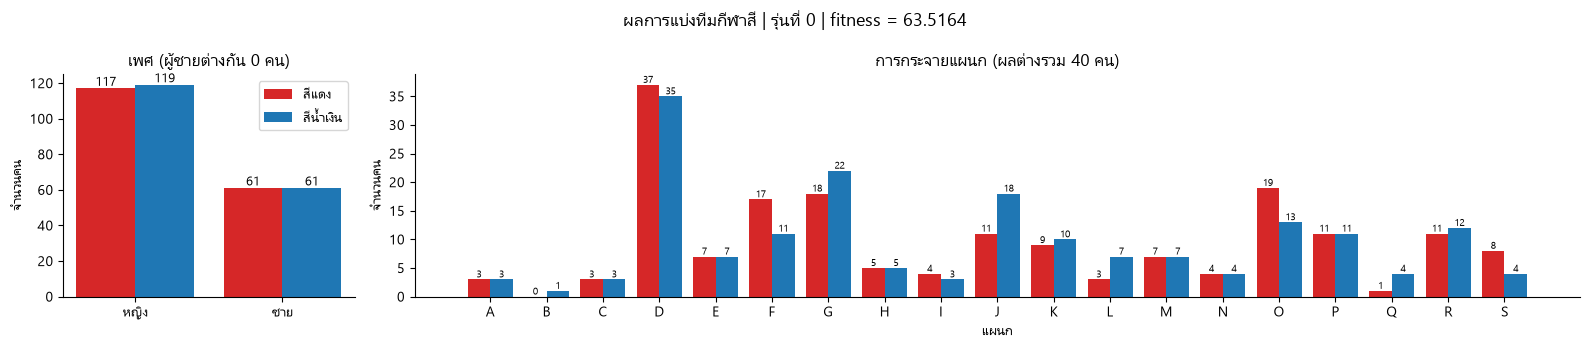

รุ่นที่    0 | fitness = 63.5164


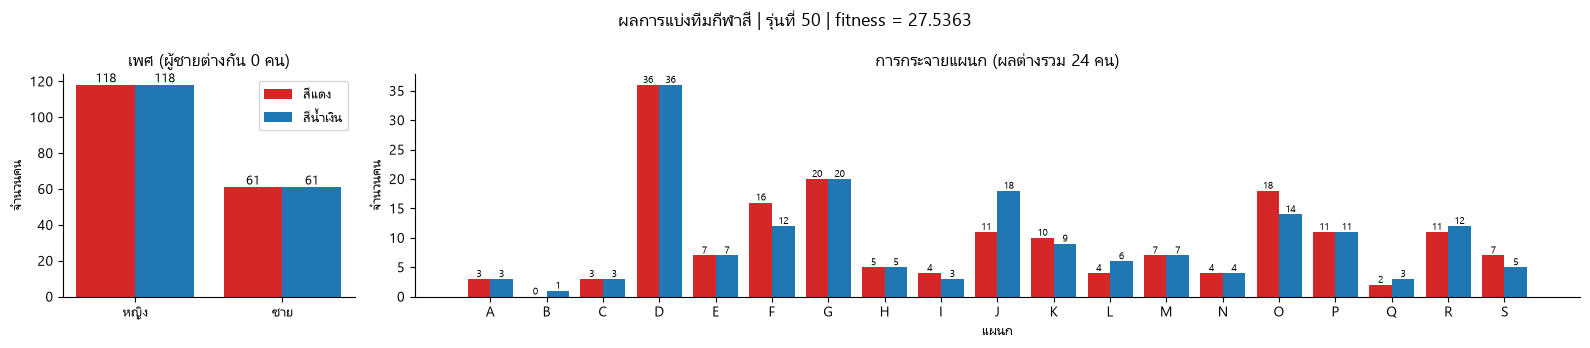

รุ่นที่   50 | fitness = 27.5363


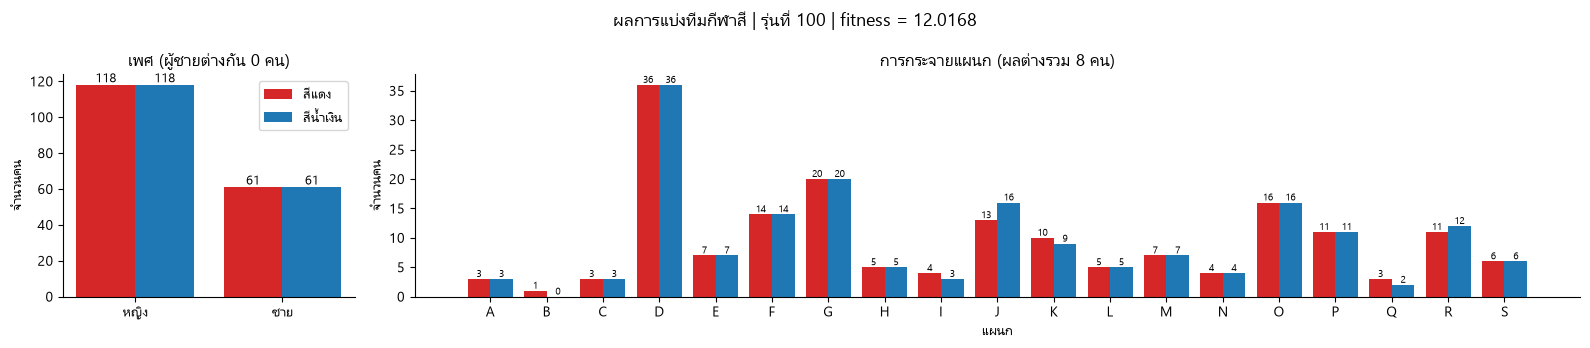

รุ่นที่  100 | fitness = 12.0168


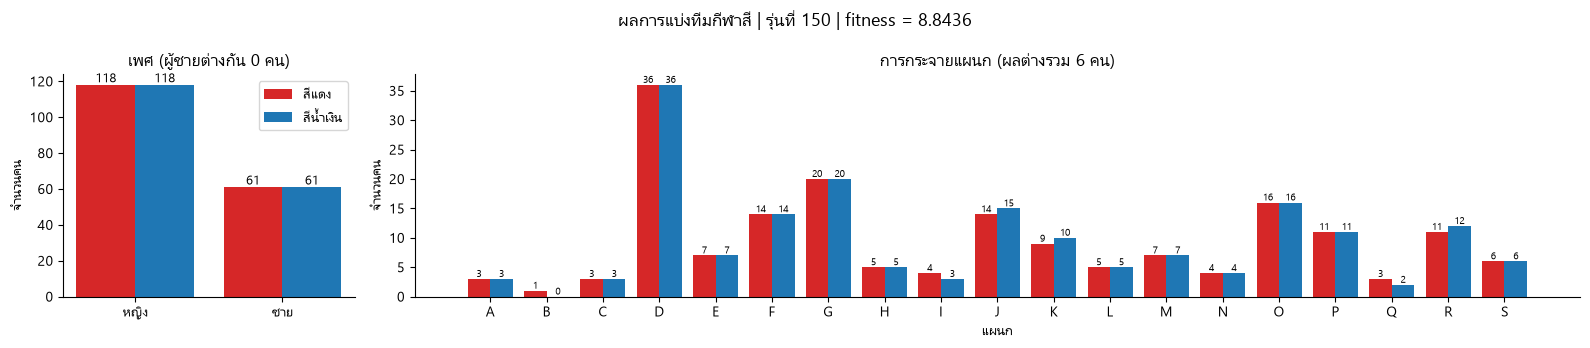

รุ่นที่  150 | fitness = 8.8436


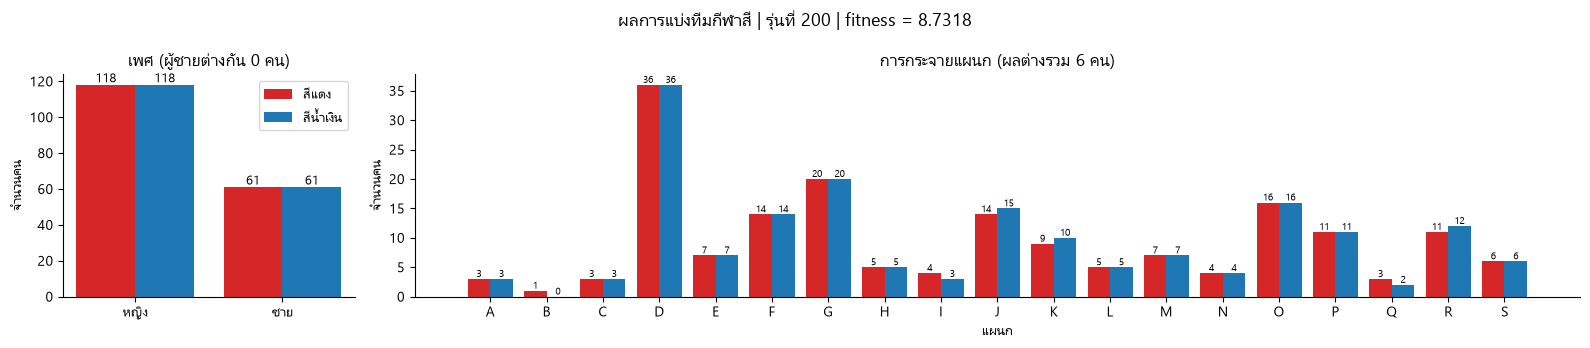

รุ่นที่  200 | fitness = 8.7318


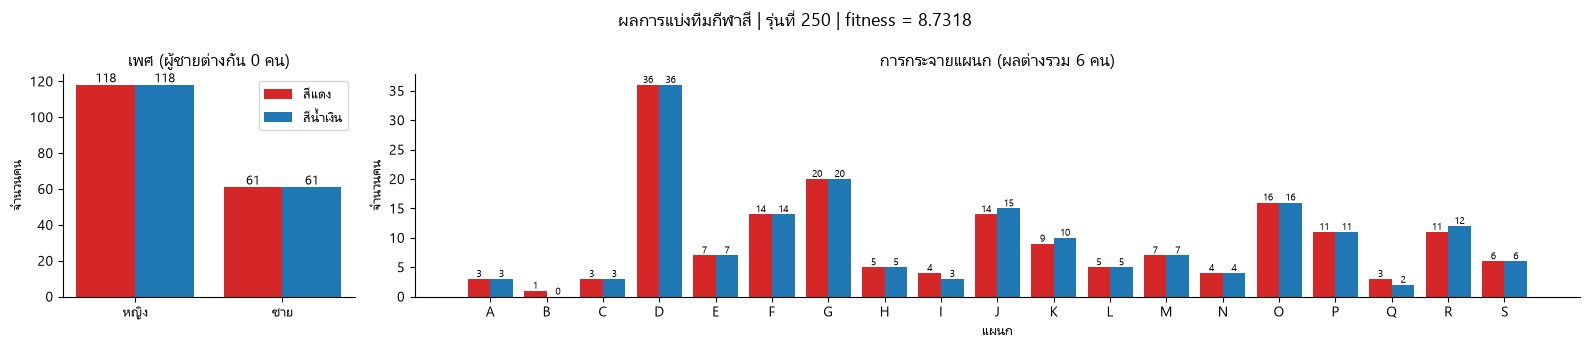

รุ่นที่  250 | fitness = 8.7318


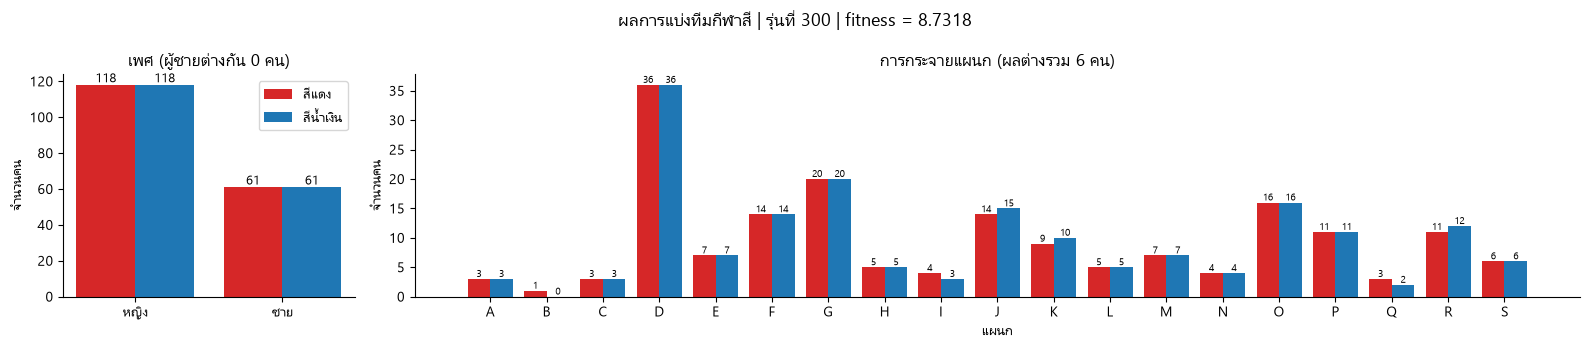

รุ่นที่  300 | fitness = 8.7318


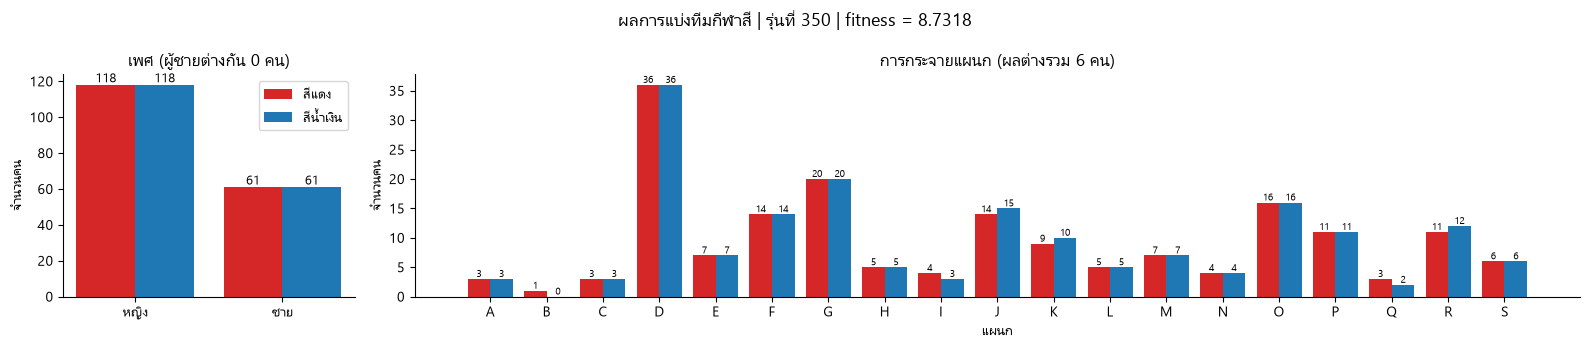

รุ่นที่  350 | fitness = 8.7318


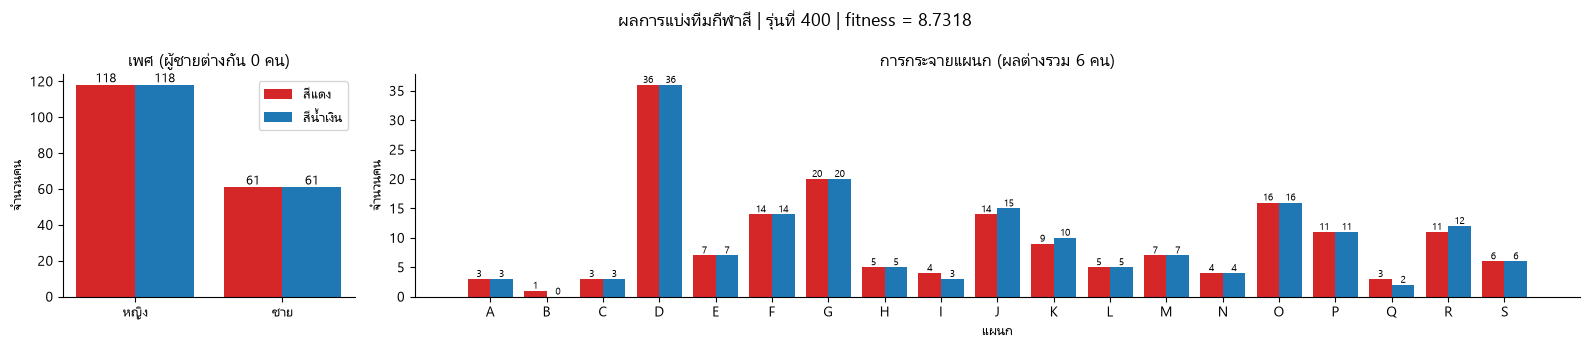

รุ่นที่  400 | fitness = 8.7318


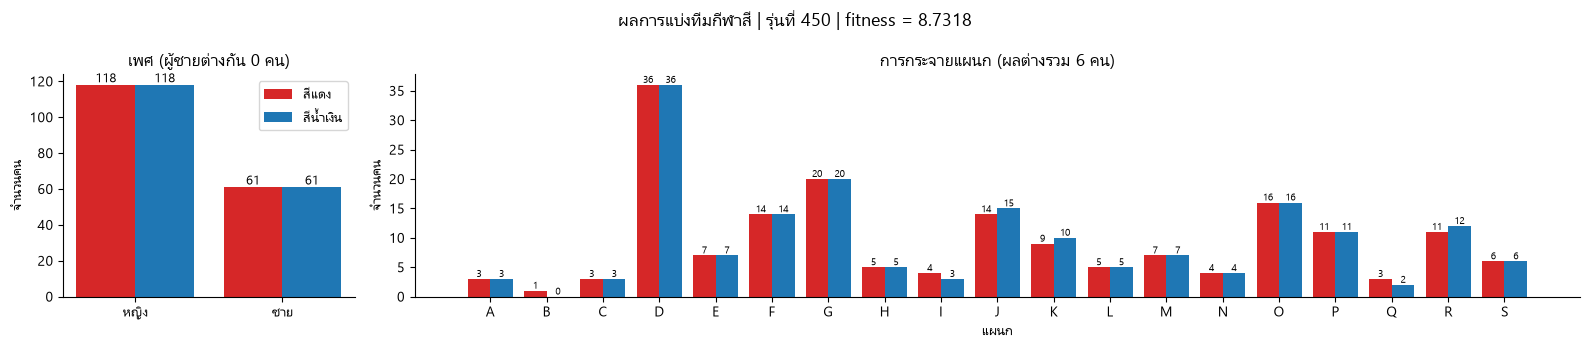

รุ่นที่  450 | fitness = 8.7318


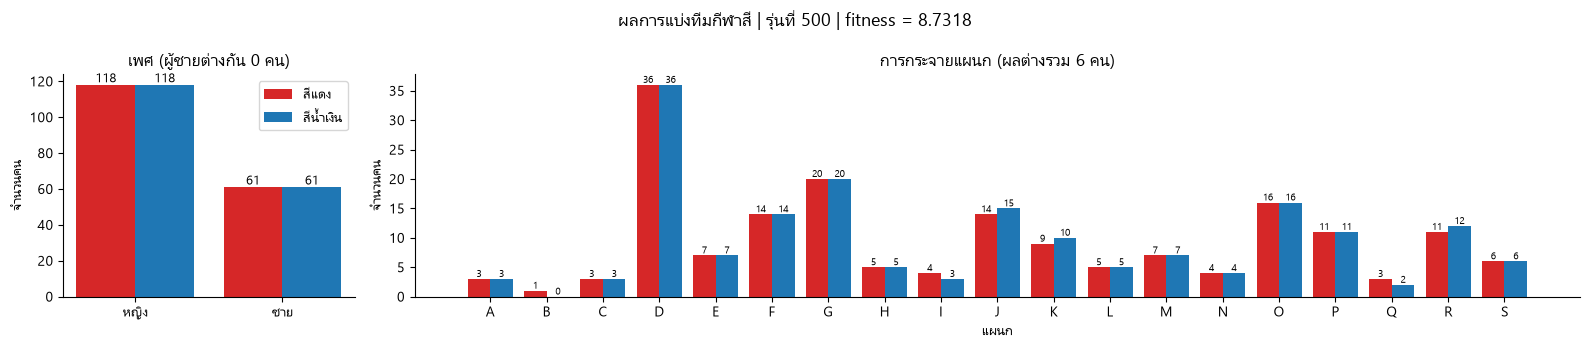

รุ่นที่  500 | fitness = 8.7318

🎉 สิ้นสุดการทำงานที่รุ่น 500 | fitness ที่ดีที่สุด = 8.7318
พนักงานจำนวน 358 คน แบ่งออกเป็น สีแดง 179 คน | สีน้ำเงิน 179 คน
ผลต่างค่าเฉลี่ยอายุ: 0.61 ปี (แดง: 40.9 | น้ำเงิน: 41.5)
ผลต่างค่าน้ำหนัก: 0.75 กก. (แดง: 72.5 | น้ำเงิน: 71.7)
ผลต่างค่าส่วนสูง: 0.02 ซม. (แดง: 167.9 | น้ำเงิน: 167.9)
ผลต่างเพศชาย: 0 คน (แดง: 61 | น้ำเงิน: 61)
ผลต่างการกระจายแผนก: 6 คน (จาก 19 แผนก)


In [31]:
# ฟังก์ชันตรวจสอบเงื่อนไขการหยุด พร้อมพิมพ์สรุปผลลัพธ์การแบ่งสี
def is_stop(gen, max_gen, pop, best_score):
    if gen >= max_gen:
        best = pop[0]
        red = (best == 0)
        blue = (best == 1)
        
        diff_age = abs(ages[red].mean() - ages[blue].mean())
        diff_weight = abs(weights[red].mean() - weights[blue].mean())
        diff_height = abs(heights[red].mean() - heights[blue].mean())
        diff_gender = abs(is_male[red].sum() - is_male[blue].sum())
        diff_dept = np.sum(np.abs(dept_dummies[red].sum(axis=0) - dept_dummies[blue].sum(axis=0)))
        
        print(f"\n🎉 สิ้นสุดการทำงานที่รุ่น {gen} | fitness ที่ดีที่สุด = {best_score:.4f}")
        print(f"พนักงานจำนวน {len(df)} คน แบ่งออกเป็น สีแดง {red.sum()} คน | สีน้ำเงิน {blue.sum()} คน")
        print(f"ผลต่างค่าเฉลี่ยอายุ: {diff_age:.2f} ปี (แดง: {ages[red].mean():.1f} | น้ำเงิน: {ages[blue].mean():.1f})")
        print(f"ผลต่างค่าน้ำหนัก: {diff_weight:.2f} กก. (แดง: {weights[red].mean():.1f} | น้ำเงิน: {weights[blue].mean():.1f})")
        print(f"ผลต่างค่าส่วนสูง: {diff_height:.2f} ซม. (แดง: {heights[red].mean():.1f} | น้ำเงิน: {heights[blue].mean():.1f})")
        print(f"ผลต่างเพศชาย: {diff_gender} คน (แดง: {is_male[red].sum()} | น้ำเงิน: {is_male[blue].sum()})")
        print(f"ผลต่างการกระจายแผนก: {diff_dept} คน (จาก {df['department'].nunique()} แผนก)")
        return True
    return False

# ฟังก์ชันการคัดสรรทางธรรมชาติ (Genetic Algorithm Loop)
def natural_selection(pop, max_gen=500, k=50, mutation_rate=0.8):
    gen = 0
    while True:
        # วัดผล 
        f = fitness(pop)
        
        # คัดเลือก: จัดลำดับจากคะแนนดีที่สุดไปแย่ที่สุด
        i = np.argsort(f)
        pop = pop[i]
        best_score = f[i[0]]
        
        # แสดงผลทุก 50 รุ่น
        if gen % 50 == 0:
            visturization(pop[0], gen, best_score, full=False)
            print(f"รุ่นที่ {gen:4d} | fitness = {best_score:.4f}")
            
        # ตรวจสอบเงื่อนไขการหยุด
        if is_stop(gen, max_gen, pop, best_score):
            break
            
        gen += 1
        
        # สืบพันธุ์: สุ่มพ่อแม่จากกลุ่ม Top k มาสร้างลูกแทนที่ครึ่งหลัง
        for idx in range(k, len(pop)):
            p1 = pop[np.random.randint(0, k)]
            p2 = pop[np.random.randint(0, k)]
            child = sexual(p1, p2)
            
            # มีโอกาสกลายพันธุ์ 
            if np.random.rand() < mutation_rate:
                child = asexual(child)
                
            pop[idx] = child

    best_dna = pop[0]
    return best_dna

# รันฟังก์ชันเพื่อหาคำตอบที่ดีที่สุด
pop = generate_pop_asimetry(100)
best_dna = natural_selection(pop)

#### แสดงผลลัพธ์สุดท้าย

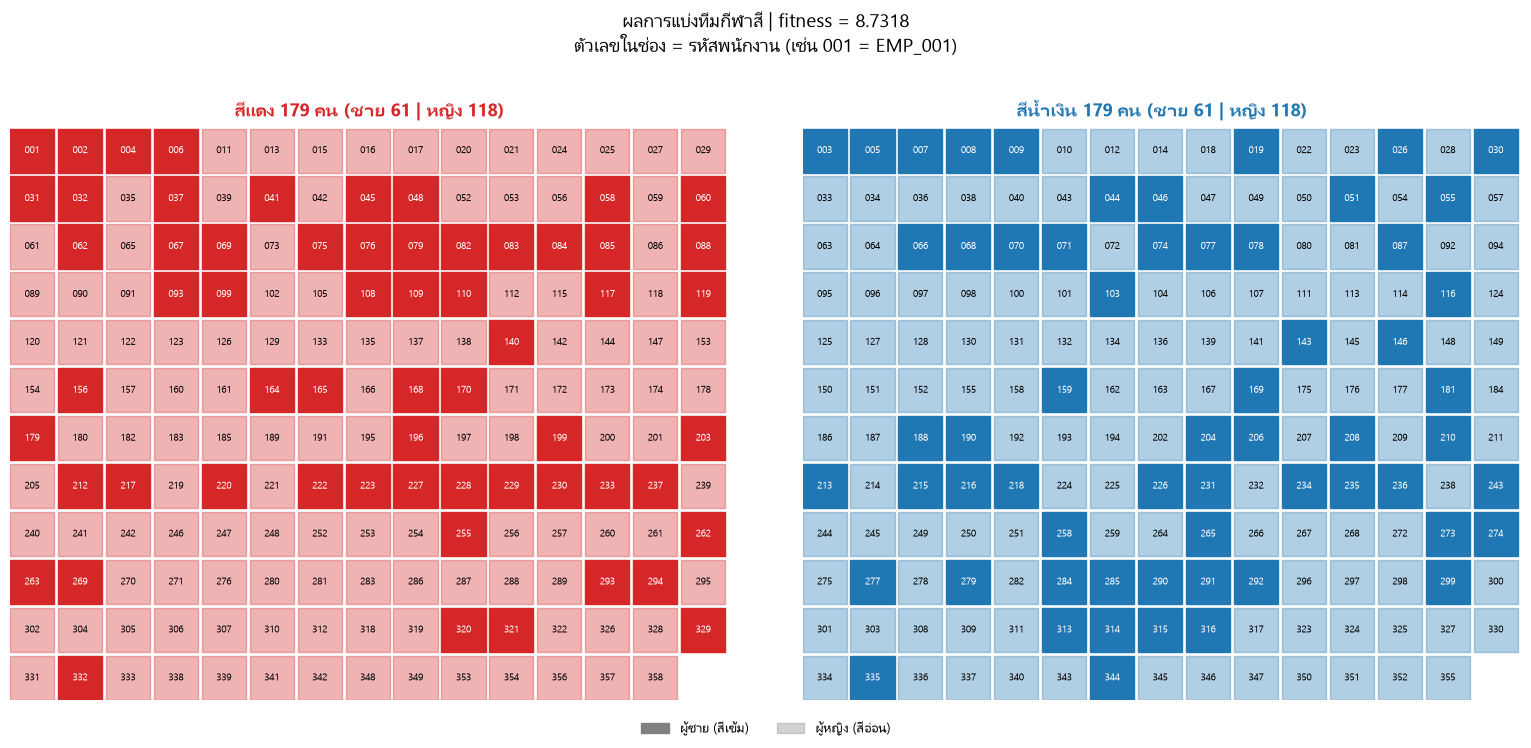

,สีแดง,สีน้ำเงิน
0,EMP_001,EMP_003
1,EMP_002,EMP_005
2,EMP_004,EMP_007
3,EMP_006,EMP_008
4,EMP_011,EMP_009
...,...,...
174,EMP_353,EMP_347
175,EMP_354,EMP_350
176,EMP_356,EMP_351
177,EMP_357,EMP_352


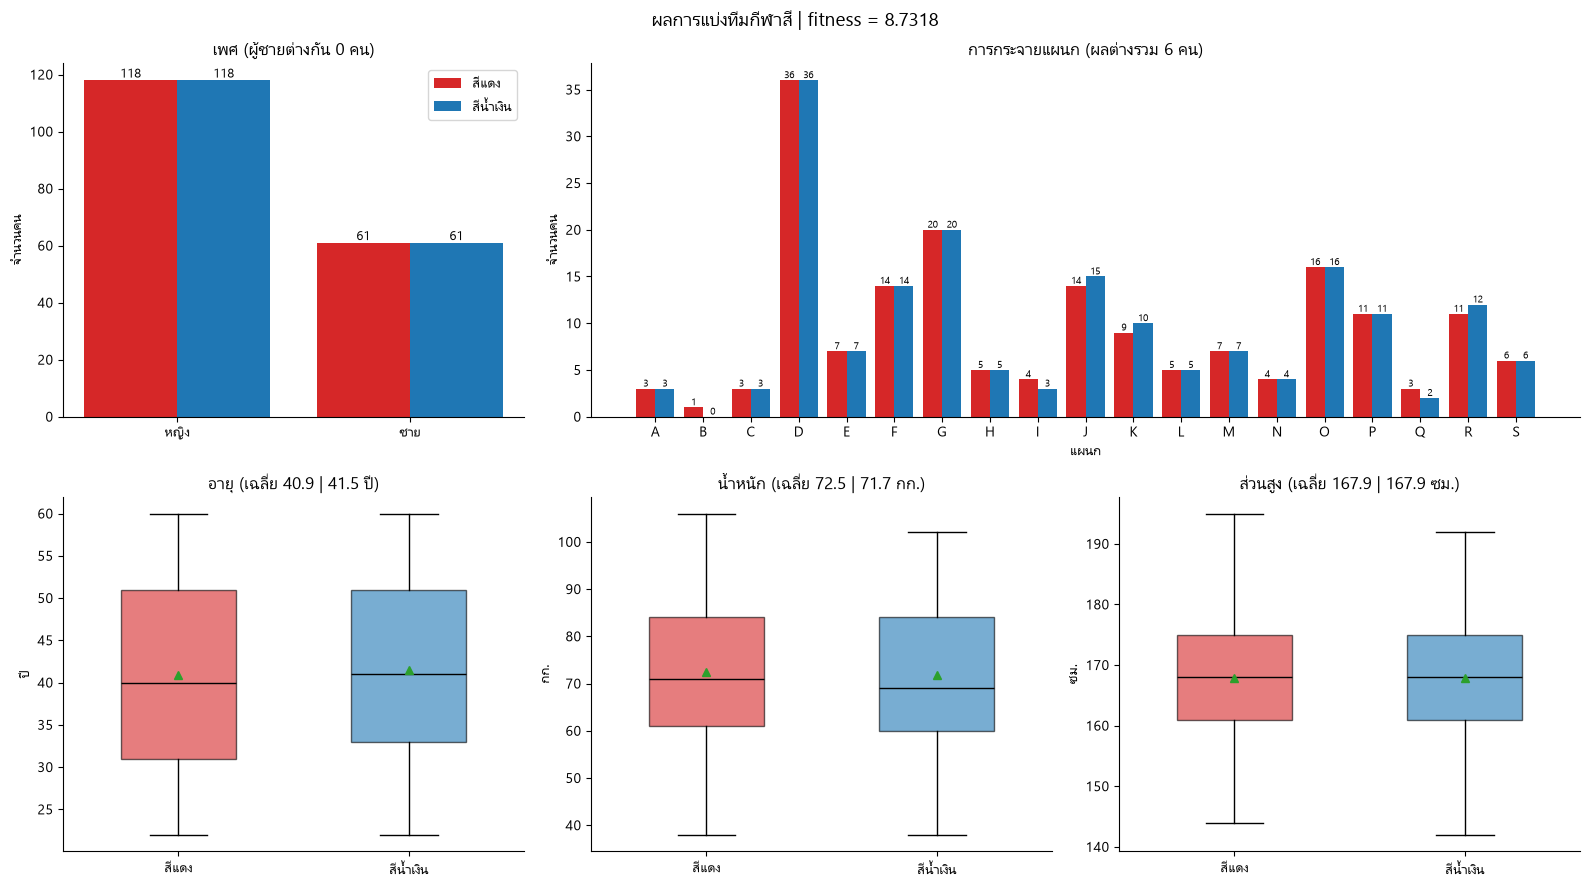

บันทึกผลลัพธ์ลงไฟล์ team_result.csv แล้ว


In [32]:
# แสดงผลการแบ่งทีมที่ดีที่สุดแบบเต็ม (รายชื่อพนักงานแต่ละสี + กราฟเปรียบเทียบทั้งหมด)
final_table = visturization(best_dna, best_score=evaluate_single(best_dna), full=True)

# บันทึกรายชื่อพนักงานพร้อมสีลงไฟล์ CSV (utf-8-sig เพื่อให้เปิดใน Excel แล้วภาษาไทยไม่เพี้ยน)
final_table.to_csv('team_result.csv', index=False, encoding='utf-8-sig')
print('บันทึกผลลัพธ์ลงไฟล์ team_result.csv แล้ว')

In [ ]:
# Heatmap แสดงจำนวนพนักงานแต่ละอายุ แยกตามสีทีม
age_data = final_table[['age', 'team']].copy()
age_data['age'] = pd.to_numeric(age_data['age'], errors='coerce')
age_data = age_data.dropna(subset=['age'])
age_values = np.arange(int(age_data['age'].min()), int(age_data['age'].max()) + 1)
age_counts = pd.crosstab(age_data['team'], age_data['age']).reindex(
    index=list(TEAM_NAMES.values()), columns=age_values, fill_value=0
)

fig, axes = plt.subplots(2, 1, figsize=(16, 4), sharex=True, constrained_layout=True)
max_count = max(1, int(age_counts.to_numpy().max()))
for ax, (code, name), cmap in zip(axes, TEAM_NAMES.items(), ['Reds', 'Blues']):
    counts = age_counts.loc[name].to_numpy()
    image = ax.imshow([counts], aspect='auto', cmap=cmap, vmin=0, vmax=max_count)
    ax.set_yticks([0], [name])
    for x, count in enumerate(counts):
        ax.text(x, 0, str(count), ha='center', va='center', fontsize=8,
                color='white' if count > max_count * 0.6 else 'black')
    fig.colorbar(image, ax=ax, label='จำนวนคน')
axes[-1].set_xticks(np.arange(len(age_values)), age_values, rotation=90)
axes[-1].set_xlabel('อายุ (ปี)')
fig.suptitle('การกระจายอายุของสีแดงและสีน้ำเงิน')
plt.show()

In [ ]:
# กราฟกระจายน้ำหนักและส่วนสูง แยกสีตามทีม
fig, ax = plt.subplots(figsize=(10, 7))
for code, name in TEAM_NAMES.items():
    members = final_table[final_table['team'] == name]
    ax.scatter(members['weight'], members['height'],
               color=TEAM_COLORS[code], label=name, alpha=0.55, s=35)
ax.set_xlabel('น้ำหนัก (กก.)')
ax.set_ylabel('ส่วนสูง (ซม.)')
ax.set_title('การกระจายน้ำหนักและส่วนสูงของแต่ละสี')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()